# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

## 一、实验环境与提交要求

### 1.1 身份与环境记录

In [2]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

STUDENT_ID = 20244080107

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python课程
[学号] 20244080107
[机器指纹] 025bce21d5564943
[RUN_ID] 20244080107-025bce21d5564943


## 二、实验内容与过程

### 实验1：NumPy 数组、数据类型与索引

#### 1.1 创建不同数据类型的数组

In [4]:
# bonjour

integer_array = np.array([1, 2, 3])
float_array = np.array([1.5, 2.5, 3.5])
boolean_array = np.array([True, False, True])

arrays = {
    "整数数组": integer_array,
    "浮点数数组": float_array,
    "布尔数组": boolean_array,
}

for name, array in arrays.items():
    print(f"{name}: dtype={array.dtype}, shape={array.shape}, ndim={array.ndim}")

python_list = [1, 2.5, True]
numpy_array = np.array(python_list)

print("Python 列表中各元素的类型：", [type(value).__name__ for value in python_list])
print("混合数据转换成 NumPy 数组后：", numpy_array)
print("转换后的 dtype：", numpy_array.dtype)

整数数组: dtype=int64, shape=(3,), ndim=1
浮点数数组: dtype=float64, shape=(3,), ndim=1
布尔数组: dtype=bool, shape=(3,), ndim=1
Python 列表中各元素的类型： ['int', 'float', 'bool']
混合数据转换成 NumPy 数组后： [1.  2.5 1. ]
转换后的 dtype： float64


三个 NumPy 数组分别保存整数、浮点数和布尔值；它们的形状都是 `(3,)`，维度都是 `1`。Python 列表可以包含不同类型的元素，而 NumPy 数组通常会把元素统一为一种数据类型，因此混合数据创建数组时可能发生类型转换。

#### 1.2 改变数组形状

In [6]:
numbers = np.arange(12)

array_2d = numbers.reshape(3, 4)
array_3d = numbers.reshape(2, 3, 2)

print("原始一维数组：")
print(numbers)

print("\n形状为 (3, 4) 的数组：")
print(array_2d)

print("\n形状为 (2, 3, 2) 的数组：")
print(array_3d)

print("\n元素总数:", numbers.size, array_2d.size, array_3d.size)

原始一维数组：
[ 0  1  2  3  4  5  6  7  8  9 10 11]

形状为 (3, 4) 的数组：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状为 (2, 3, 2) 的数组：
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

元素总数: 12 12 12


`np.arange(12)` 创建了 12 个从 0 到 11 的整数。`reshape` 改变数组的形状，但不改变元素总数，因此新形状中各维度的乘积必须等于原数组的元素个数：`3 × 4 = 12`，`2 × 3 × 2 = 12`。三个数组的元素总数因此都是 12。

#### 1.3 数组索引与筛选

In [7]:
# 取第 2 行
second_row = array_2d[1, :]

# 取第 1 至第 3 列（包含第 3 列）
first_three_columns = array_2d[:, 0:3]

# 取所有大于 6 的元素
greater_than_six = array_2d[array_2d > 6]

print("第 2 行：", second_row)
print("第 2 行的 shape：", second_row.shape)

print("\n第 1 至第 3 列：")
print(first_three_columns)
print("切片的 shape：", first_three_columns.shape)

print("\n大于 6 的元素：", greater_than_six)
print("筛选结果的 shape：", greater_than_six.shape)

第 2 行： [4 5 6 7]
第 2 行的 shape： (4,)

第 1 至第 3 列：
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
切片的 shape： (3, 3)

大于 6 的元素： [ 7  8  9 10 11]
筛选结果的 shape： (5,)


`array_2d[1, :]` 取出第 2 行，结果是一维数组，形状为 `(4,)`。`array_2d[:, 0:3]` 取所有行的第 1 至第 3 列，切片右端不包含索引 3，所以结果形状是 `(3, 3)`。布尔条件 `array_2d > 6` 筛选出值为 7 到 11 的元素，结果是一维数组，形状为 `(5,)`。

#### 1.4 使用逻辑条件筛选元素

In [8]:
numbers_0_to_9 = np.arange(10)

less_than_2_or_greater_than_7 = numbers_0_to_9[
    (numbers_0_to_9 < 2) | (numbers_0_to_9 > 7)
]

greater_than_3_and_less_than_7 = numbers_0_to_9[
    (numbers_0_to_9 > 3) & (numbers_0_to_9 < 7)
]

print("原数组：", numbers_0_to_9)
print("小于 2 或大于 7：", less_than_2_or_greater_than_7)
print("大于 3 且小于 7：", greater_than_3_and_less_than_7)

原数组： [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7： [0 1 8 9]
大于 3 且小于 7： [4 5 6]


第一个条件选出小于 2 或大于 7 的元素，因此结果为 `[0, 1, 8, 9]`。第二个条件选出大于 3 且小于 7 的元素，因此结果为 `[4, 5, 6]`。NumPy 中组合逐元素条件时，使用 `|` 表示“或”、`&` 表示“且”，每个比较条件都需要用括号括起来。

#### 1.5 逐元素乘法与矩阵乘法

In [9]:
matrix_a = np.array([[1, 2],
                     [3, 4]])

matrix_b = np.array([[5, 6],
                     [7, 8]])

print("使用 * 逐元素相乘：")
print(matrix_a * matrix_b)

print("\n使用 np.multiply() 逐元素相乘：")
print(np.multiply(matrix_a, matrix_b))

print("\n使用 @ 进行矩阵乘法：")
print(matrix_a @ matrix_b)

print("\n使用 np.matmul() 进行矩阵乘法：")
print(np.matmul(matrix_a, matrix_b))

使用 * 逐元素相乘：
[[ 5 12]
 [21 32]]

使用 np.multiply() 逐元素相乘：
[[ 5 12]
 [21 32]]

使用 @ 进行矩阵乘法：
[[19 22]
 [43 50]]

使用 np.matmul() 进行矩阵乘法：
[[19 22]
 [43 50]]


`*` 和 `np.multiply()` 会把对应位置的元素分别相乘，结果为 `[[5, 12], [21, 32]]`。`@` 和 `np.matmul()` 执行矩阵乘法，按行与列计算，结果为 `[[19, 22], [43, 50]]`。因此，逐元素乘法与矩阵乘法含义不同。

### 实验2：随机抽样、统计与缺失值

#### 2.1 生成模拟成绩并计算统计量

In [10]:
rng = np.random.default_rng(42)

scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数：", scores.size)
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std())
print("极差：", np.ptp(scores))

样本数： 1000
最小值： 33.51587174785217
最大值： 100.0
均值： 69.70929595324685
标准差： 9.881580939490172
极差： 66.48412825214783


`rng.normal` 生成了 1,000 个均值为 70、标准差为 10 的模拟成绩；固定随机种子 `42` 可以让结果可复现。`np.clip` 将低于 0 的值设为 0、超过 100 的值设为 100。输出包含样本数、最小值、最大值、均值、标准差和极差；极差等于最大值减最小值。

#### 2.2 比较均匀抽样与加权抽样

In [11]:
population = np.arange(1, 11)
rng_sample = np.random.default_rng(2026)

uniform_sample = rng_sample.choice(
    population,
    size=5,
    replace=False
)

weights = population / population.sum()
weighted_sample = rng_sample.choice(
    population,
    size=5,
    replace=False,
    p=weights
)

print("总体：", population)
print("均匀抽样：", uniform_sample)
print("按数值大小加权抽样：", weighted_sample)

总体： [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样： [9 4 2 6 1]
按数值大小加权抽样： [ 9 10  4  8  6]


`replace=False` 表示不放回抽样，因此每个结果中不会重复。均匀抽样时，每个整数被选中的概率相同；加权抽样时，整数越大，权重越高、被选中的概率越大。随机种子固定为 `2026`，所以重复运行时结果相同。

#### 2.3 随机排列与原地打乱

In [12]:
rng_shuffle = np.random.default_rng(2026)

original_array = np.arange(1, 11)
permuted_array = rng_shuffle.permutation(original_array)

print("使用 permutation 后，原数组：", original_array)
print("permutation 返回的新数组：", permuted_array)

array_to_shuffle = original_array.copy()
print("\nshuffle 前：", array_to_shuffle)
rng_shuffle.shuffle(array_to_shuffle)
print("shuffle 后：", array_to_shuffle)

使用 permutation 后，原数组： [ 1  2  3  4  5  6  7  8  9 10]
permutation 返回的新数组： [ 2 10  1  7  9  4  6  3  8  5]

shuffle 前： [ 1  2  3  4  5  6  7  8  9 10]
shuffle 后： [ 4  1  5 10  2  6  3  7  8  9]


`permutation()` 返回随机排列后的新数组，原数组保持不变；`shuffle()` 则直接改变传入数组本身。代码固定了随机种子 `2026`，因此随机排列结果可复现。

#### 2.4 缺失值与均值比较

In [13]:
scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan

ordinary_mean = np.mean(scores_with_nan)
mean_without_nan = np.nanmean(scores_with_nan)
missing_count = np.isnan(scores_with_nan).sum()

valid_scores = scores_with_nan[~np.isnan(scores_with_nan)]

print("缺失值个数：", missing_count)
print("普通均值：", ordinary_mean)
print("忽略缺失值后的均值：", mean_without_nan)
print("有效成绩数量：", valid_scores.size)

缺失值个数： 3
普通均值： nan
忽略缺失值后的均值： 69.71315691233939
有效成绩数量： 997


第 10、20、30 个成绩被设置为 `np.nan`，因此缺失值个数为 3。普通的 `np.mean()` 遇到 `nan` 会返回 `nan`；`np.nanmean()` 会忽略缺失值并计算其余成绩的平均值。`valid_scores` 保存了不含缺失值的成绩，后续绘图时可以直接使用。

#### 2.5 整理含缺失值的成绩表

In [14]:
score_table = pd.DataFrame(
    {"成绩": scores_with_nan},
    index=np.arange(1, scores_with_nan.size + 1)
)
score_table.index.name = "序号"

print("表格形状：", score_table.shape)
print("前 5 条记录：")
print(score_table.head())

print("\n第 10、20、30 个成绩：")
print(score_table.loc[[10, 20, 30]])

表格形状： (1000, 1)
前 5 条记录：
           成绩
序号           
1   73.047171
2   59.600159
3   77.504512
4   79.405647
5   50.489648

第 10、20、30 个成绩：
    成绩
序号    
10 NaN
20 NaN
30 NaN


`score_table` 将模拟成绩和对应序号整理成 pandas DataFrame。表格有 1,000 行、1 列；第 10、20、30 个成绩仍为缺失值 `NaN`。该变量只保存在 Notebook 的内存中，没有写入磁盘，可在后续代码单元中继续使用。

### 实验3：SciPy 数值计算与 Matplotlib 可视化

#### 3.1 求解线性方程组

In [15]:
from scipy.linalg import solve

# 方程组：3x + y = 9，x + 2y = 8
coefficients = np.array([
    [3, 1],
    [1, 2]
])

constants = np.array([9, 8])

solution = solve(coefficients, constants)
x, y = solution

print(f"x = {x}")
print(f"y = {y}")
print("代入左侧计算结果：", coefficients @ solution)
print("方程右侧常数：", constants)
print("验证是否成立：", np.allclose(coefficients @ solution, constants))

x = 2.000000000000001
y = 2.9999999999999996
代入左侧计算结果： [9. 8.]
方程右侧常数： [9 8]
验证是否成立： True


SciPy 的 `solve()` 求得 `x = 2`、`y = 3`。将解代入方程组后，左侧计算结果为 `[9, 8]`，与右侧常数一致；`np.allclose()` 输出 `True`，表示验证通过。

#### 3.2 使用 root 求方程的根

In [16]:
from scipy.optimize import root

def equation(values):
    x = values[0]
    return [x**2 - 2]

positive_result = root(equation, x0=[1.0])
negative_result = root(equation, x0=[-1.0])

print("正根求解成功：", positive_result.success)
print("正根：", positive_result.x[0])
print("正根处的函数值：", equation(positive_result.x)[0])

print("\n负根求解成功：", negative_result.success)
print("负根：", negative_result.x[0])
print("负根处的函数值：", equation(negative_result.x)[0])

正根求解成功： True
正根： 1.4142135623730947
正根处的函数值： -8.881784197001252e-16

负根求解成功： True
负根： -1.4142135623730947
负根处的函数值： -8.881784197001252e-16


`root()` 根据初始猜测值搜索方程的根。初始值为 `1.0` 时，结果应接近正根 `√2`；初始值为 `-1.0` 时，结果应接近负根 `-√2`。`success` 为 `True` 表示求解器报告成功；根处的函数值应接近 `0`。

3.2这个单元运行时间要比前面的时间长一点

#### 3.3 使用 minimize 求函数最小值

In [17]:
from scipy.optimize import minimize

def objective(values):
    x = values[0]
    return x**2 + 2 * x + 2

result = minimize(objective, x0=[0.0])

minimum_x = result.x[0]
minimum_value = result.fun

print("求解成功：", result.success)
print("极小点 x：", minimum_x)
print("函数最小值：", minimum_value)

# 解析结果：x² + 2x + 2 = (x + 1)² + 1
print("解析结果：极小点 x = -1，最小值 = 1")

求解成功： True
极小点 x： -1.00000000944232
函数最小值： 1.0
解析结果：极小点 x = -1，最小值 = 1


`minimize()` 从初始值 `x0 = 0` 开始搜索函数的极小点。数值结果应接近 `x = -1`，函数值应接近 `1`。配方可得 `x² + 2x + 2 = (x + 1)² + 1`，因此解析结果也是极小点 `-1`、最小值 `1`；数值优化结果与解析结果相符。

#### 3.4 独立样本 t 检验

In [18]:
from scipy.stats import ttest_ind

rng_test = np.random.default_rng(2026)

sample_group_1 = rng_test.normal(loc=0, scale=1, size=100)
sample_group_2 = rng_test.normal(loc=1, scale=1, size=100)

test_result = ttest_ind(sample_group_1, sample_group_2)

print("t 统计量：", test_result.statistic)
print("p 值：", test_result.pvalue)

if test_result.pvalue < 0.05:
    print("判断：在 0.05 显著性水平下，两组均值存在显著差异。")
else:
    print("判断：在 0.05 显著性水平下，没有足够证据认为两组均值存在显著差异。")

t 统计量： -6.817514303621474
p 值： 1.093384351623396e-10
判断：在 0.05 显著性水平下，两组均值存在显著差异。


两组样本分别来自均值为 0 和均值为 1、标准差均为 1 的正态分布。固定随机种子 `2026` 可使抽样结果可复现。独立样本 t 检验输出 t 统计量和 p 值；当 p 值小于 `0.05` 时，认为两组均值在该显著性水平下存在显著差异，否则表示没有足够证据认定均值不同。

#### 3.5 使用 Matplotlib 绘图

Matplotlib is building the font cache; this may take a moment.


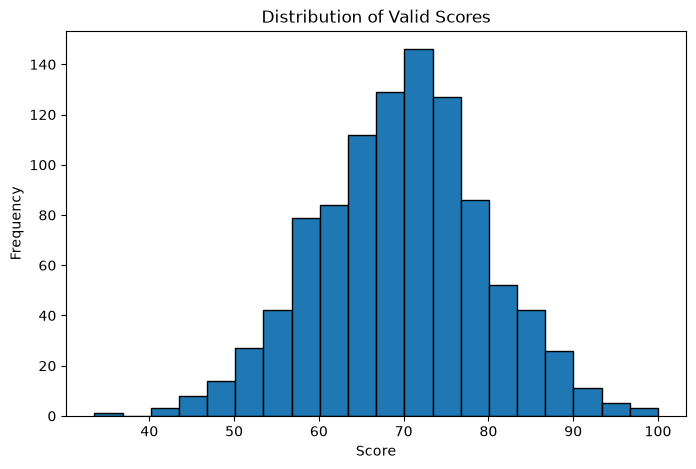

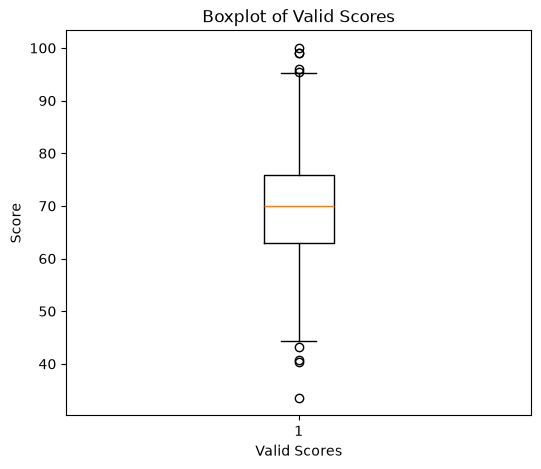

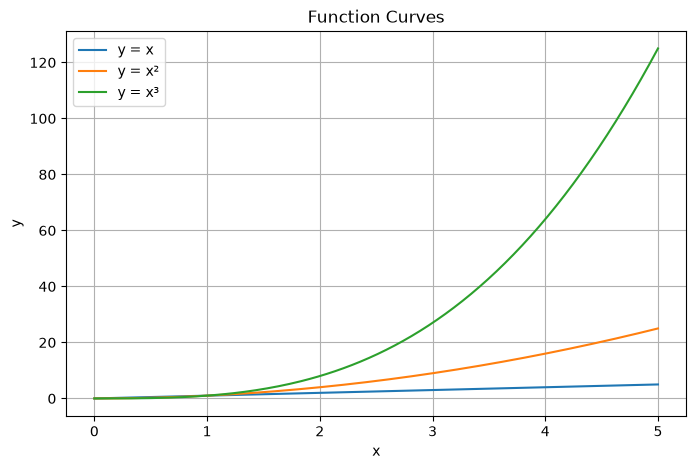

In [19]:
import matplotlib.pyplot as plt

# 有效成绩直方图
plt.figure(figsize=(8, 5))
plt.hist(valid_scores, bins=20, edgecolor="black")
plt.title("Distribution of Valid Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

# 有效成绩箱线图
plt.figure(figsize=(6, 5))
plt.boxplot(valid_scores)
plt.title("Boxplot of Valid Scores")
plt.xlabel("Valid Scores")
plt.ylabel("Score")
plt.show()

# y=x、y=x²、y=x³ 函数图
x_values = np.linspace(0, 5, 200)

plt.figure(figsize=(8, 5))
plt.plot(x_values, x_values, label="y = x")
plt.plot(x_values, x_values**2, label="y = x²")
plt.plot(x_values, x_values**3, label="y = x³")
plt.title("Function Curves")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

直方图展示有效成绩在不同分数区间内的数量分布；箱线图概括成绩的中位数、四分位数和可能的离群值。函数图在 `0 ≤ x ≤ 5` 的范围内同时绘制 `y = x`、`y = x²` 和 `y = x³`，并用图例区分曲线。三张图都设置了标题和坐标轴标签，并直接显示在 Notebook 中。

### 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

#### 4.1 创建学生成绩 DataFrame

In [20]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

student_df = pd.DataFrame(records).set_index("Name")

score_columns = ["Math", "English", "Python"]
student_df["Total"] = student_df[score_columns].sum(axis=1)
student_df["Average"] = student_df[score_columns].mean(axis=1)

print("行索引：", student_df.index.tolist())
print("列名：", student_df.columns.tolist())

print("\n前 3 行：")
print(student_df.head(3))

print("\n基本统计信息：")
print(student_df.describe())

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


DataFrame 以学生姓名作为行索引，并包含组别、三科成绩、总分和平均分。`Total` 是每名学生三科成绩之和，`Average` 是三科成绩的算术平均值。`describe()` 输出数值列的计数、均值、标准差、最小值、四分位数和最大值；文本列 `Group` 不会出现在默认统计结果中。

#### 4.2 使用 loc、iloc 和条件筛选

In [21]:
print("使用 loc 读取 Carol：")
print(student_df.loc["Carol"])

print("\n使用 iloc 读取 Carol：")
print(student_df.iloc[2])

high_average_students = student_df[student_df["Average"] >= 80]

print("\n平均分不低于 80 的学生：")
print(high_average_students)

使用 loc 读取 Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

使用 iloc 读取 Carol：
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


`loc` 根据行索引标签读取数据，因此用 `student_df.loc["Carol"]` 获取 Carol 的记录。`iloc` 根据从 0 开始的位置编号读取数据；Carol 是第 3 行，所以使用 `student_df.iloc[2]`。条件筛选保留平均分不低于 80 的学生。

#### 4.3 计算列均值和行均值

In [22]:
subject_scores = student_df[["Math", "English", "Python"]]

column_means = subject_scores.mean(axis=0)
row_means = subject_scores.mean(axis=1)

print("三科各自的平均分：")
print(column_means)

print("\n每名学生的三科平均分：")
print(row_means)

三科各自的平均分：
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生的三科平均分：
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


`mean(axis=0)` 沿行方向计算，得到每门科目在所有学生中的平均分；`mean(axis=1)` 沿列方向计算，得到每名学生三科成绩的平均分。行均值应与 DataFrame 中之前计算的 `Average` 列一致。

#### 4.4 使用 apply、agg 和 rank 汇总成绩

In [23]:
# 对每名学生，按行计算三科成绩的最高分、最低分和平均分
student_summary = subject_scores.apply(
    lambda row: pd.Series({
        "最高分": row.max(),
        "最低分": row.min(),
        "平均分": row.mean(),
    }),
    axis=1
)

print("每名学生的三科成绩汇总：")
print(student_summary)

# 对每科成绩，一次计算最小值、均值和最大值
subject_summary = subject_scores.agg(["min", "mean", "max"])

print("\n每科成绩的最小值、均值和最大值：")
print(subject_summary)

# 按 Math 成绩从高到低排名
math_ranking = subject_scores["Math"].rank(
    ascending=False,
    method="min"
).astype(int)

print("\n数学成绩排名（名次相同时并列）：")
print(math_ranking.sort_values())

每名学生的三科成绩汇总：
        最高分   最低分        平均分
Name                        
Alice  95.0  88.0  91.000000
Bob    80.0  68.0  73.333333
Carol  91.0  85.0  88.333333
David  73.0  65.0  69.333333
Eva    92.0  79.0  85.666667
Frank  84.0  77.0  81.000000

每科成绩的最小值、均值和最大值：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

数学成绩排名（名次相同时并列）：
Name
Carol    1
Alice    2
Frank    3
Eva      4
Bob      5
David    6
Name: Math, dtype: int64


`apply(..., axis=1)` 逐行处理成绩，得到每名学生三科的最高分、最低分和平均分。`agg(["min", "mean", "max"])` 一次计算每科成绩的最小值、均值和最大值。`rank(ascending=False)` 按数学成绩从高到低排名；如果出现并列，`method="min"` 会给并列学生相同的较前名次。

#### 4.5 按组统计成绩

In [24]:
group_summary = student_df.groupby("Group").agg(
    人数=("Group", "size"),
    数学平均分=("Math", "mean"),
    英语平均分=("English", "mean"),
    Python平均分=("Python", "mean"),
)

print("各组人数和三科平均分：")
print(group_summary)

student_df["所在组Python平均分"] = (
    student_df.groupby("Group")["Python"].transform("mean")
)

print("\n每名学生及其所在组的 Python 平均分：")
print(student_df[["Group", "Python", "所在组Python平均分"]])

各组人数和三科平均分：
       人数      数学平均分      英语平均分  Python平均分
Group                                     
A       3  79.666667  83.333333  87.000000
B       3  80.000000  78.333333  80.333333

每名学生及其所在组的 Python 平均分：
      Group  Python  所在组Python平均分
Name                             
Alice     A      95     87.000000
Bob       A      80     87.000000
Carol     B      89     80.333333
David     B      70     80.333333
Eva       A      86     87.000000
Frank     B      82     80.333333


`groupby("Group")` 按 A、B 组划分学生；`agg()` 汇总每组人数和三科平均分。`transform("mean")` 计算每组的 Python 平均分，并将该组的平均值对应到组内每一名学生，因此新增列中的同组学生会显示相同的组平均分。

#### 4.6 筛选 Python 平均分不低于 80 的组

In [25]:
qualified_groups = student_df.groupby("Group").filter(
    lambda group: group["Python"].mean() >= 80
)

print("保留的组：", sorted(qualified_groups["Group"].unique()))
print("\n保留组中的学生：")
print(qualified_groups[["Group", "Python"]])

保留的组： ['A', 'B']

保留组中的学生：
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82


`groupby("Group").filter(...)` 会按组计算 Python 平均分，并保留组平均分不低于 80 的所有学生。A 组的 Python 平均分为 87，B 组约为 80.33，因此两个组都会保留。

#### 4.7 成绩的协方差与相关系数

In [26]:
covariance_matrix = subject_scores.cov()
correlation_matrix = subject_scores.corr()

print("三科成绩的协方差矩阵：")
print(covariance_matrix)

print("\n三科成绩的皮尔森相关系数矩阵：")
print(correlation_matrix)

print("\n数学与英语成绩的协方差：",
      covariance_matrix.loc["Math", "English"])
print("数学与英语成绩的相关系数：",
      correlation_matrix.loc["Math", "English"])

三科成绩的协方差矩阵：
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

三科成绩的皮尔森相关系数矩阵：
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000

数学与英语成绩的协方差： 62.56666666666668
数学与英语成绩的相关系数： 0.6535293080615485


协方差的正负表示两门成绩是否倾向于同向变化：正值表示一门成绩较高时，另一门也倾向较高；负值表示倾向反向变化。协方差的数值会受到成绩尺度影响，不适合直接比较关系强弱。

皮尔森相关系数在 -1 到 1 之间。绝对值越接近 1，线性相关越强；越接近 0，线性相关越弱。数学与英语成绩的协方差为正，相关系数也为正，说明这组数据中两科成绩呈同向变化。相关不代表因果关系。